# Exploratory data analysis

Profile the raw student survey, check missing values and anomalies, and visualize feature distributions and their relationships with mental-health risk. This notebook reports anomalies without removing rows.


In [1]:
from pathlib import Path

import pandas as pd



student_df = pd.read_csv("../data/raw/student_mental_health.csv")


In [2]:
print("les premieres lignes :")
display(student_df.head())

print(f"\nDimensions de donn?es : {student_df.shape[0]} lignes et {student_df.shape[1]} colonnes\n")
student_df.info()


les premieres lignes :


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium



Dimensions de donn?es : 2000 lignes et 17 colonnes

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float

In [11]:
missing_counts = student_df.isna().sum()
missing_percent = (missing_counts / len(student_df)).round(2)
missing_df = pd.DataFrame(
    {"Valeurs manquantes": missing_counts, "Pourcentage (%)": missing_percent*100}
)

print("Colonnes avec des valeurs manquantes :")
display(
    missing_df[missing_df["Valeurs manquantes"] > 0]
    .sort_values("Valeurs manquantes", ascending=False)
)
print(f"\nNombre de lignes dupliques : {student_df.duplicated().sum()}")


Colonnes avec des valeurs manquantes :


,Valeurs manquantes,Pourcentage (%)
Financial_Stress,91,5.0
Diet_Quality,69,3.0
Sleep_Hours,62,3.0
Social_Media_Hours,58,3.0
Family_Support,54,3.0
Attendance_Rate,47,2.0
GPA,38,2.0



Nombre de lignes dupliqu?es : 0


In [16]:
print("Statistiques :")
display(student_df.describe(include="number").T)


Statistiques :


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [59]:
incoherence = {
    "Age": ((student_df["Age"] < 15) | (student_df["Age"] > 40)).sum(),
    "Sleep hours": ((student_df["Sleep_Hours"] < 0) | (student_df["Sleep_Hours"] > 24)).sum(),
    "GPA": ((student_df["GPA"] < 0) | (student_df["GPA"] > 4)).sum(),
    "Prsence": ((student_df["Attendance_Rate"] < 0) | (student_df["Attendance_Rate"] > 100)).sum(),
    "Social_Media_Hours > Screen_Time_Hours": (student_df["Social_Media_Hours"] > student_df["Screen_Time_Hours"]).sum(),
}

for col, count in incoherence.items():
    print(f"{col}: {count}")


student_df = student_df[(student_df['Social_Media_Hours']<student_df['Screen_Time_Hours']) | student_df['Social_Media_Hours'].isna()]


Age: 0
Sleep hours: 0
GPA: 0
Prsence: 0
Social_Media_Hours > Screen_Time_Hours: 0


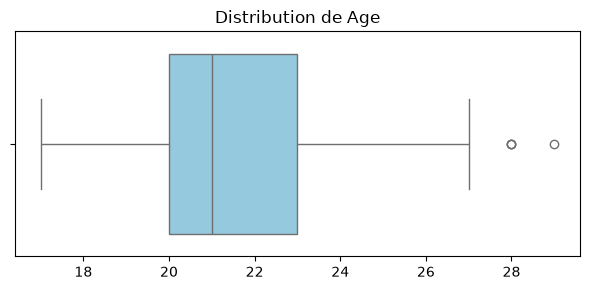

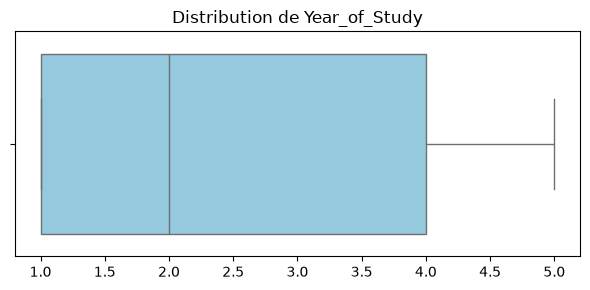

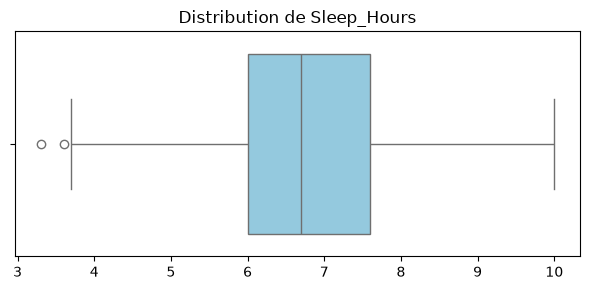

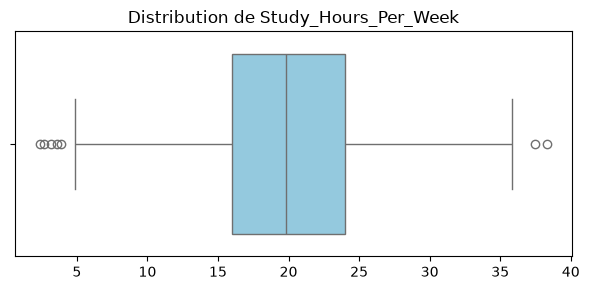

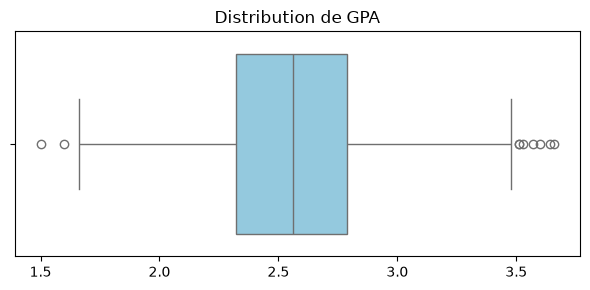

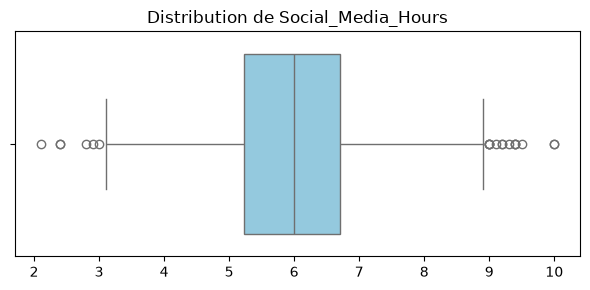

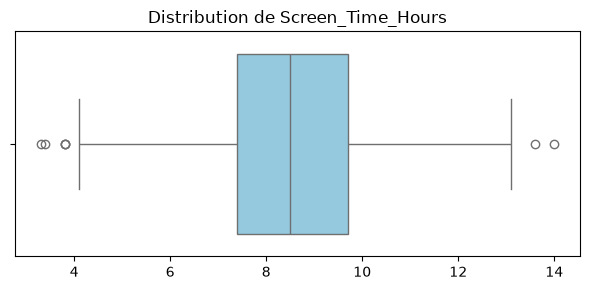

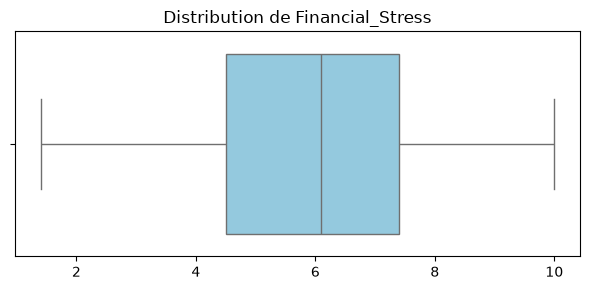

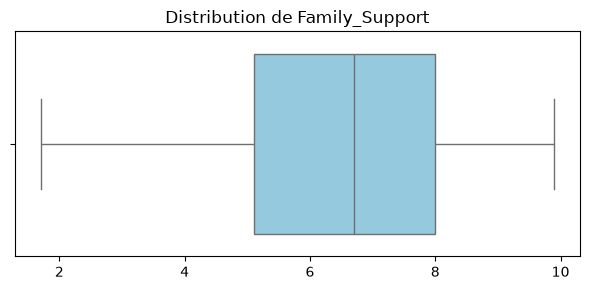

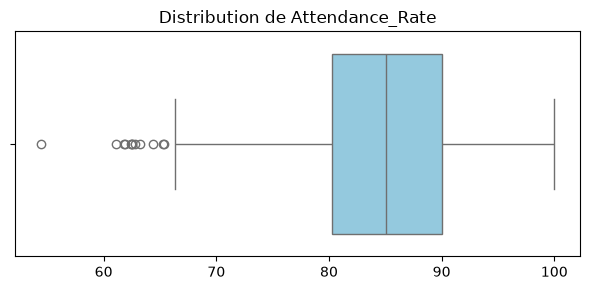

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = student_df.select_dtypes(include="number").columns

for column in numeric_columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=student_df[column], color="skyblue")
    plt.title(f"Distribution de {column}")
    plt.xlabel("")
    plt.tight_layout()
    plt.show()


In [22]:
outliers_summary = []

for column in numeric_columns:
    q1 = student_df[column].quantile(0.25)
    q3 = student_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = student_df.loc[
        (student_df[column] < lower_bound) | (student_df[column] > upper_bound),
        column,
    ]
    

    outliers_summary.append(
        {
            "Variable": column,
            "lower bound": round(lower_bound, 2),
            "upper bound": round(upper_bound, 2),
            "Nbr outliers": len(outliers),
            "Outliers values": sorted(outliers.tolist()),
        }
    )

display(pd.DataFrame(outliers_summary))


,Variable,lower bound,upper bound,Nbr outliers,Outliers values
0,Age,15.50,27.50,4,"[28, 28, 28, 29]"
1,Year_of_Study,-3.50,8.50,0,[]
2,Sleep_Hours,3.60,10.00,2,"[3.3, 3.6]"
3,Study_Hours_Per_Week,4.00,36.00,7,"[2.4, 2.7, 3.2, 3.6, 3.9, 37.5, 38.3]"
4,GPA,1.61,3.50,9,"[1.5, 1.6, 3.51, 3.51, 3.53, 3.57, 3.6, 3.64, ..."
5,Social_Media_Hours,3.01,8.91,20,"[2.1, 2.4, 2.4, 2.8, 2.9, 3.0, 9.0, 9.0, 9.0, ..."
6,Screen_Time_Hours,3.95,13.15,7,"[3.3, 3.4, 3.8, 3.8, 3.8, 13.6, 14.0]"
7,Financial_Stress,0.15,11.75,0,[]
8,Family_Support,0.75,12.35,0,[]
9,Attendance_Rate,65.75,104.55,12,"[54.4, 61.1, 61.8, 61.9, 62.4, 62.5, 62.5, 62...."


In [26]:
numeric_stats = student_df[numeric_columns].describe().T
print("Statistiques des variables num :")
display(numeric_stats)

categorical_columns = student_df.select_dtypes(exclude="number").columns
print("Statistiques des variables cat :")
display(student_df[categorical_columns].describe().T)


Statistiques des variables num?riques :


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


Statistiques des variables cat :


,count,unique,top,freq
Student_ID,2000,2000,STU0001,1
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


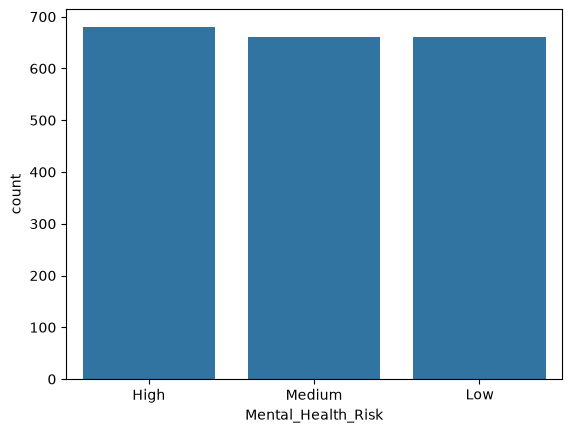

In [29]:
print(student_df["Mental_Health_Risk"].value_counts())
sns.countplot(data=student_df, x="Mental_Health_Risk")
plt.show()


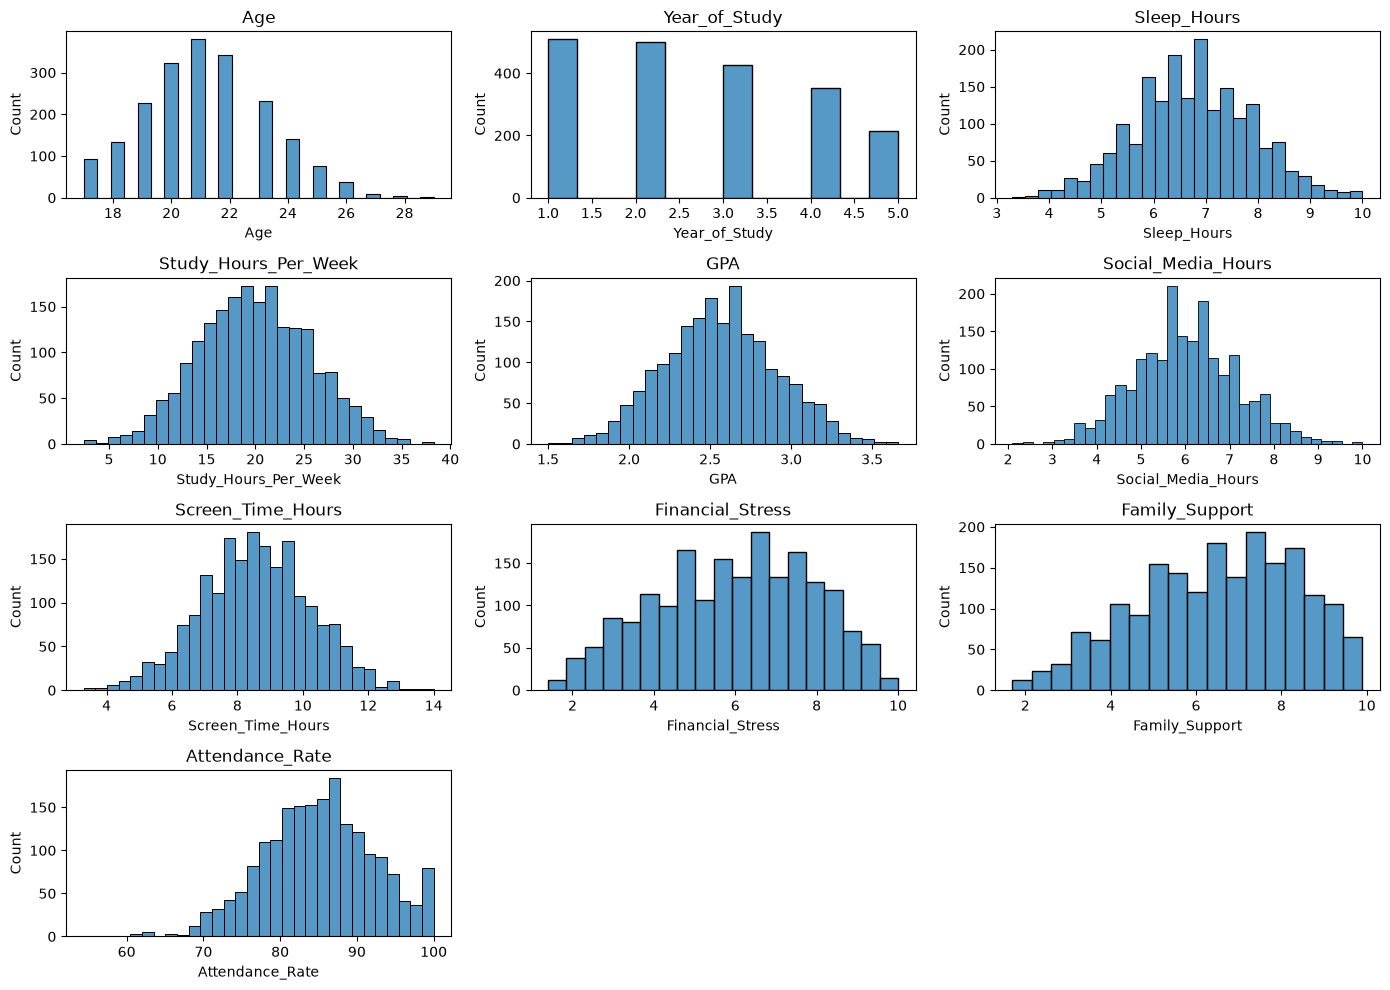

In [38]:
plt.figure(figsize=(14, 10))
for index, column in enumerate(numeric_columns, 1):
    plt.subplot(4, 3, index)
    sns.histplot(student_df[column])
    plt.title(column)

plt.tight_layout()
plt.show()


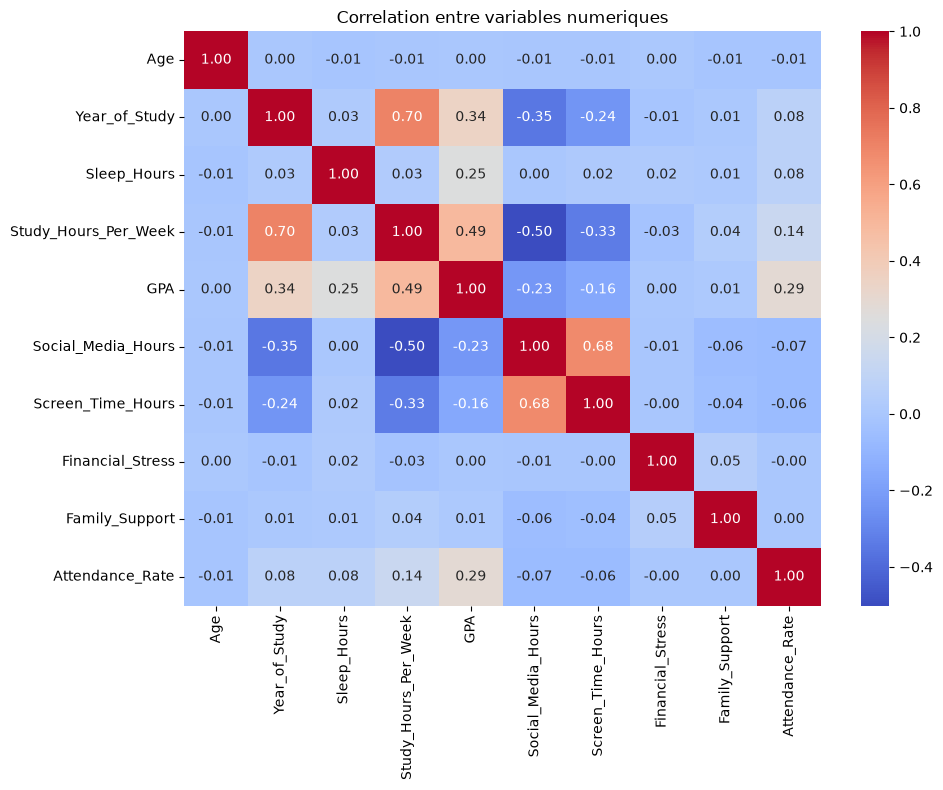

In [51]:
correlation_matrix = student_df[numeric_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
)
plt.title("Correlation entre variables numeriques")
plt.tight_layout()
plt.show()


In [56]:
risk_order = {"Low": 0, "Medium": 1, "High": 2}
student_df["mental_health_risk_ordinal"] = student_df["Mental_Health_Risk"].map(risk_order)

print(
    student_df.select_dtypes(include="number")
    .corr()["mental_health_risk_ordinal"]
)


Age                           0.004961
Year_of_Study                -0.166404
Sleep_Hours                  -0.541857
Study_Hours_Per_Week         -0.238793
GPA                          -0.352626
Social_Media_Hours            0.207601
Screen_Time_Hours             0.173972
Financial_Stress              0.313547
Family_Support               -0.250894
Attendance_Rate              -0.145362
mental_health_risk_ordinal    1.000000
Name: mental_health_risk_ordinal, dtype: float64
